# **ML FED Funds Predictor - ML Time Series Analysis**

WARNING: This notebook may take like 30 min to run.
### Import required libraries:

In [112]:
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import glob
import os
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
import shap
from sklearn.inspection import permutation_importance
from itertools import product
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

### Load the raw datasets from the dictionary:

In [113]:
target_dir = "../data/"
excel_files = glob.glob(os.path.join(target_dir, "*.xlsx"))

raw_data = {}

for file in excel_files:
    name = os.path.basename(file).split('.')[0]

    df = pd.read_excel(file)
    date_col = [col for col in df.columns if 'observation_date' in col.lower() or 'date' in col.lower()][0]

    df[date_col] = pd.to_datetime(df[date_col])
    df.set_index(date_col, inplace=True)
    df.sort_index(inplace=True)

    raw_data[name] = df
    print(f"Loaded {name} with {len(df)} rows.")

Loaded LSEG-INFL-MONTH with 434 rows.
Loaded FRED-FEDFUNDS-MONTH with 435 rows.
Loaded LSEG-EURUSD-DAY with 9448 rows.
Loaded FRED-GDPC1-QUAT with 144 rows.
Loaded LSEG-US3MT-DAY with 9001 rows.
Loaded LSEG-AUspot-DAY with 9428 rows.
Loaded FRED-NROU-QUAT with 145 rows.
Loaded LSEG-OILfut-DAY with 8758 rows.
Loaded LSEG-US10YT-DAY with 9001 rows.
Loaded LSEG-GASfut-DAY with 9002 rows.
Loaded LSEG-OILold-WEEK with 73 rows.
Loaded FRED-UNRATE-MONTH with 435 rows.


### **Data Cleaning and Preprocessing:**

In [114]:
def downsample_to_monthly(data_dict: dict, freq: str = "DAY") -> None:
    daily_keys = [k for k in data_dict.keys() if k.endswith("-" + freq)]
    for key in daily_keys:
        df = data_dict[key]
        col = df.columns[0]
        m_stats = df.groupby([df.index.year, df.index.month])[col].agg(['mean', 'std', 'min', 'max'])
        new_df = pd.DataFrame(index=m_stats.index)
        new_df["MEAN-"+key] = m_stats['mean']
        new_df["STDEV-"+key] = m_stats['std']
        new_df["REALRANGE-"+key] = (m_stats['max'] - m_stats['min']) / m_stats['mean']
        new_df.index = [pd.Timestamp(year=y, month=m, day=1) for y, m in new_df.index]
        data_dict[key.replace("-" + freq, "-MONTH")] = new_df
        data_dict.pop(key)

downsample_to_monthly(raw_data, "DAY")
downsample_to_monthly(raw_data, "WEEK")

def upsample_to_monthly(data_dict: dict, freq: str = "QUAT") -> None:
    target_keys = [k for k in data_dict.keys() if k.endswith("-" + freq)]
    study_end = pd.Timestamp("2025-12-01")
    for key in target_keys:
        df = data_dict[key]
        new_index = pd.date_range(start=df.index.min(), end=study_end, freq='MS')
        df_monthly = df.reindex(new_index).ffill()
        new_key = key.replace("-" + freq, "-MONTH")
        data_dict[new_key] = df_monthly
        data_dict.pop(key)

upsample_to_monthly(raw_data, "QUAT")

In [115]:
raw_data

{'LSEG-INFL-MONTH':             USCPNY=
 Date               
 1990-01-01      5.2
 1990-02-01      5.3
 1990-03-01      5.2
 1990-04-01      4.7
 1990-05-01      4.4
 ...             ...
 2025-10-01      3.0
 2025-11-01      2.7
 2025-12-01      2.7
 2026-01-01      2.4
 2026-02-01      2.4
 
 [434 rows x 1 columns],
 'FRED-FEDFUNDS-MONTH':                   FEDFUNDS
 observation_date          
 1990-01-01            8.23
 1990-02-01            8.24
 1990-03-01            8.28
 1990-04-01            8.26
 1990-05-01            8.18
 ...                    ...
 2025-11-01            3.88
 2025-12-01            3.72
 2026-01-01            3.64
 2026-02-01            3.64
 2026-03-01            3.64
 
 [435 rows x 1 columns],
 'FRED-UNRATE-MONTH':                   UNRATE
 observation_date        
 1990-01-01           5.4
 1990-02-01           5.3
 1990-03-01           5.2
 1990-04-01           5.4
 1990-05-01           5.4
 ...                  ...
 2025-11-01           4.5
 2025-12-01 

In [116]:
df_new = raw_data['LSEG-OILfut-MONTH'].copy()
df_old = raw_data['LSEG-OILold-MONTH'].copy()

generic_cols = ['MEAN', 'STDEV', 'REALRANGE']
df_new.columns = generic_cols
df_old.columns = generic_cols

oil_complete = pd.concat([df_new, df_old], axis=0)
oil_complete = oil_complete.sort_index().groupby(level=0).last()
oil_complete.columns = [f"{c}-LSEG-OIL-MONTH" for c in generic_cols]

raw_data['LSEG-OIL-MONTH'] = oil_complete
raw_data.pop('LSEG-OILfut-MONTH', None)
raw_data.pop('LSEG-OILold-MONTH', None)
print(raw_data['LSEG-OIL-MONTH'].head(20))

            MEAN-LSEG-OIL-MONTH  STDEV-LSEG-OIL-MONTH  \
1990-01-01            23.092000              0.394930   
1990-02-01            21.732500              0.488765   
1990-03-01            20.292500              0.161323   
1990-04-01            18.280000              0.564225   
1990-05-01            18.252500              0.710651   
1990-06-01            16.982500              0.368816   
1990-07-01            19.794000              2.968675   
1990-08-01            28.272500              2.013560   
1990-09-01            34.185000              4.201877   
1990-10-01            35.696000              2.955432   
1990-11-01            31.105000              2.253065   
1990-12-01            26.304000              0.982105   
1991-01-01            22.307500              3.465375   
1991-02-01            20.022500              1.752263   
1991-03-01            19.762500              0.363994   
1991-04-01            21.044000              0.619379   
1991-05-01            21.213333

In [117]:
target_keys = [k for k in raw_data.keys() if k.endswith("-MONTH")]

dfs_to_merge = [raw_data[k].copy() for k in target_keys]

dataset = pd.concat(dfs_to_merge, axis=1, join='inner')
dataset = dataset.apply(pd.to_numeric, errors='coerce')

dataset = dataset.astype('float64')

dataset.sort_index(inplace=True)

print(f"Merge Complete. Shape: {dataset.shape}")
print(dataset.info())

dataset.to_excel("./WrangledData.xlsx", sheet_name="Dataset")

Merge Complete. Shape: (428, 23)
<class 'pandas.DataFrame'>
DatetimeIndex: 428 entries, 1990-04-01 to 2025-12-01
Data columns (total 23 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   USCPNY=                    428 non-null    float64
 1   FEDFUNDS                   428 non-null    float64
 2   UNRATE                     428 non-null    float64
 3   MEAN-LSEG-EURUSD-DAY       428 non-null    float64
 4   STDEV-LSEG-EURUSD-DAY      428 non-null    float64
 5   REALRANGE-LSEG-EURUSD-DAY  428 non-null    float64
 6   MEAN-LSEG-US3MT-DAY        428 non-null    float64
 7   STDEV-LSEG-US3MT-DAY       428 non-null    float64
 8   REALRANGE-LSEG-US3MT-DAY   428 non-null    float64
 9   MEAN-LSEG-AUspot-DAY       428 non-null    float64
 10  STDEV-LSEG-AUspot-DAY      428 non-null    float64
 11  REALRANGE-LSEG-AUspot-DAY  428 non-null    float64
 12  MEAN-LSEG-US10YT-DAY       428 non-null    float64
 13  STDEV-LSE

### Exploratory Data Analysis

In [118]:
dataset["OUTPUT-GAP"] = dataset.pop("NROU") - dataset.pop("UNRATE")
dataset = dataset.shift(1)
dataset['FEDFUNDS'] = dataset['FEDFUNDS'].shift(-1)

dataset['FEDFUNDS_LAG1'] = dataset['FEDFUNDS'].shift(1)

dataset['FEDFUNDS_DIFF'] = dataset['FEDFUNDS'].diff()
dataset['FEDFUNDS_DIFF_LAG1'] = dataset['FEDFUNDS_DIFF'].shift(1)

dataset = dataset.dropna()

dataset

,USCPNY=,FEDFUNDS,MEAN-LSEG-EURUSD-DAY,STDEV-LSEG-EURUSD-DAY,REALRANGE-LSEG-EURUSD-DAY,MEAN-LSEG-US3MT-DAY,STDEV-LSEG-US3MT-DAY,REALRANGE-LSEG-US3MT-DAY,MEAN-LSEG-AUspot-DAY,STDEV-LSEG-AUspot-DAY,...,STDEV-LSEG-GASfut-DAY,REALRANGE-LSEG-GASfut-DAY,GDPC1,MEAN-LSEG-OIL-MONTH,STDEV-LSEG-OIL-MONTH,REALRANGE-LSEG-OIL-MONTH,OUTPUT-GAP,FEDFUNDS_LAG1,FEDFUNDS_DIFF,FEDFUNDS_DIFF_LAG1
1990-06-01,4.4,8.29,1.230991,0.011962,0.033144,7.765000,0.083026,0.038635,11869.847226,90.281782,...,0.016065,0.038681,10083.855,18.252500,0.710651,0.079441,0.342991,8.18,0.11,-0.08
1990-07-01,4.7,8.15,1.224262,0.009624,0.024586,7.726111,0.043810,0.018120,11335.665510,125.453414,...,0.026667,0.055086,10083.855,16.982500,0.368816,0.049463,0.542991,8.29,-0.14,0.11
1990-08-01,4.8,8.13,1.264050,0.014896,0.046280,7.611667,0.109987,0.042041,11656.181341,160.646910,...,0.035501,0.077516,10090.569,19.794000,2.968675,0.405173,0.226903,8.15,-0.02,-0.14
1990-09-01,5.6,8.20,1.320978,0.013732,0.030886,7.441176,0.085505,0.040316,12686.406378,425.517563,...,0.047878,0.126068,10090.569,28.272500,2.013560,0.165532,0.026903,8.13,0.07,-0.02
1990-10-01,6.2,8.11,1.317095,0.010275,0.026650,7.355000,0.068277,0.039429,12558.967115,272.910087,...,0.192140,0.260127,10090.569,34.185000,4.201877,0.277022,-0.173097,8.20,-0.09,0.07
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-07-01,2.7,4.33,1.152919,0.011468,0.036082,4.334550,0.029266,0.025608,107774.476500,1155.520723,...,0.173002,0.199800,23770.976,67.326000,4.279721,0.187446,0.306906,4.33,0.00,0.00
2025-08-01,2.7,4.33,1.167200,0.010937,0.034356,4.348591,0.009210,0.007589,107367.200383,1101.014723,...,0.186657,0.174719,24026.834,67.243182,1.314405,0.071978,0.104200,4.33,0.00,0.00
2025-09-01,2.9,4.22,1.164595,0.004086,0.012451,4.225524,0.032597,0.034315,108264.498624,1040.378170,...,0.123541,0.133978,24026.834,64.019048,1.170277,0.077789,0.104200,4.33,-0.11,0.00
2025-10-01,3.0,4.09,1.173395,0.005776,0.019431,4.009048,0.056748,0.047892,117904.477409,3090.828162,...,0.133808,0.165129,24026.834,63.533810,1.115905,0.060598,0.004200,4.22,-0.13,-0.11


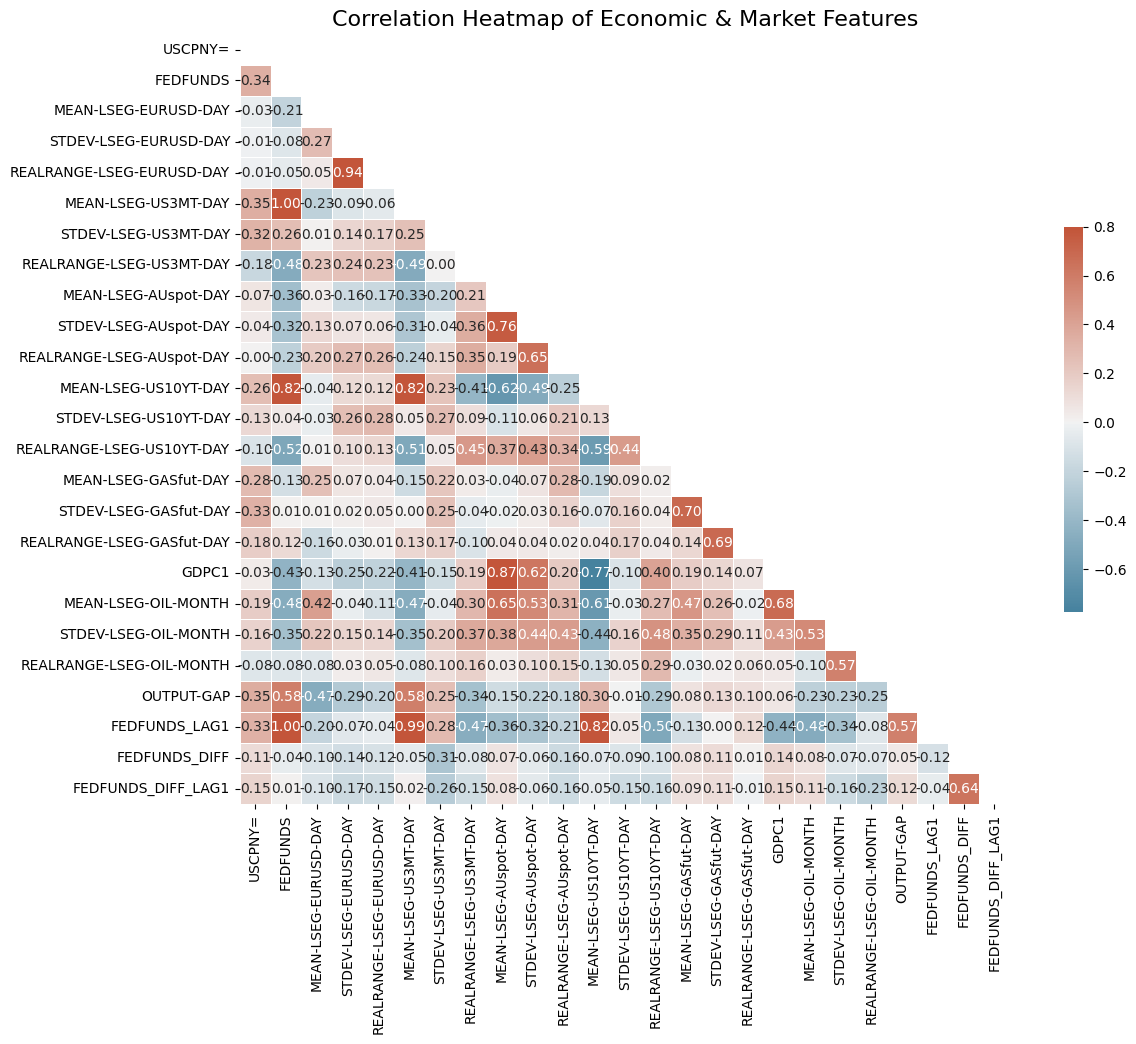

In [119]:
corr = dataset.corr()

mask = np.triu(np.ones_like(corr, dtype=bool))

f, ax = plt.subplots(figsize=(14, 10))

cmap = sns.diverging_palette(230, 20, as_cmap=True)

sns.heatmap(corr, mask=mask, cmap=cmap, vmax=.8, center=0,
            annot=True, fmt=".2f",
            square=True, linewidths=.5, cbar_kws={"shrink": .5})

plt.title('Correlation Heatmap of Economic & Market Features', fontsize=16)
plt.show()

In [120]:
corr_matrix = dataset.corr().abs()

upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

to_drop = [column for column in upper.columns if any(upper[column] > 0.85)]

threshold = 0.80
print("Pairs with Correlation > "+str(threshold)+":")
print("-" * 30)

s = upper.unstack()
so = s[s > threshold].sort_values(ascending=False)

for index, value in so.items():
    print(f"{index[0]}  <--->  {index[1]}: {value:.4f}")

Pairs with Correlation > 0.8:
------------------------------
FEDFUNDS_LAG1  <--->  FEDFUNDS: 0.9968
MEAN-LSEG-US3MT-DAY  <--->  FEDFUNDS: 0.9962
FEDFUNDS_LAG1  <--->  MEAN-LSEG-US3MT-DAY: 0.9941
REALRANGE-LSEG-EURUSD-DAY  <--->  STDEV-LSEG-EURUSD-DAY: 0.9406
GDPC1  <--->  MEAN-LSEG-AUspot-DAY: 0.8740
FEDFUNDS_LAG1  <--->  MEAN-LSEG-US10YT-DAY: 0.8207
MEAN-LSEG-US10YT-DAY  <--->  FEDFUNDS: 0.8206
MEAN-LSEG-US10YT-DAY  <--->  MEAN-LSEG-US3MT-DAY: 0.8190


In [121]:
corr_matrix = dataset.corr().abs()

upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

to_drop = [column for column in upper.columns if any(upper[column] > 0.85)]

threshold = 0.80
print("Pairs with Correlation > "+str(threshold)+":")
print("-" * 30)

s = upper.unstack()
so = s[s > threshold].sort_values(ascending=False)

for index, value in so.items():
    print(f"{index[0]}  <--->  {index[1]}: {value:.4f}")

Pairs with Correlation > 0.8:
------------------------------
FEDFUNDS_LAG1  <--->  FEDFUNDS: 0.9968
MEAN-LSEG-US3MT-DAY  <--->  FEDFUNDS: 0.9962
FEDFUNDS_LAG1  <--->  MEAN-LSEG-US3MT-DAY: 0.9941
REALRANGE-LSEG-EURUSD-DAY  <--->  STDEV-LSEG-EURUSD-DAY: 0.9406
GDPC1  <--->  MEAN-LSEG-AUspot-DAY: 0.8740
FEDFUNDS_LAG1  <--->  MEAN-LSEG-US10YT-DAY: 0.8207
MEAN-LSEG-US10YT-DAY  <--->  FEDFUNDS: 0.8206
MEAN-LSEG-US10YT-DAY  <--->  MEAN-LSEG-US3MT-DAY: 0.8190


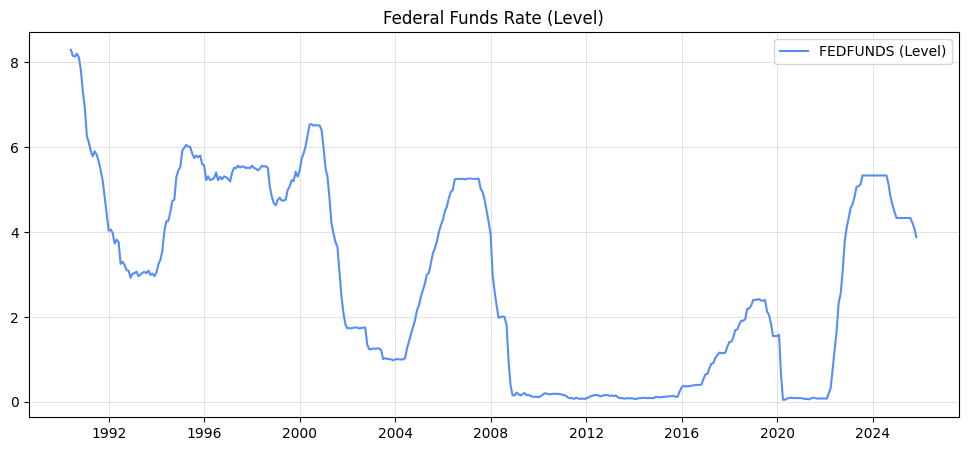

In [122]:
plt.figure(figsize=(12,5))
plt.plot(dataset.index, dataset['FEDFUNDS'], label='FEDFUNDS (Level)')
plt.title('Federal Funds Rate (Level)')
plt.legend()
plt.grid(True)
plt.show()

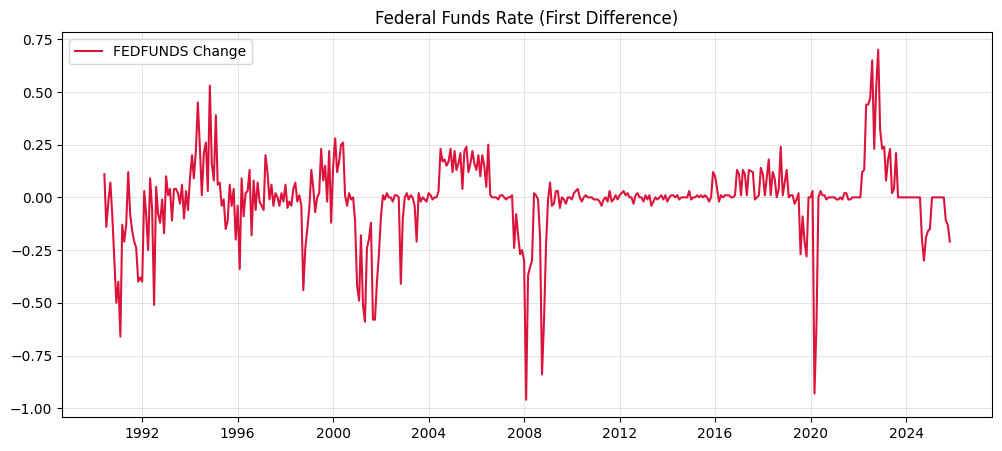

In [123]:
plt.figure(figsize=(12,5))
plt.plot(dataset.index, dataset['FEDFUNDS_DIFF'], label='FEDFUNDS Change', color='crimson')
plt.title('Federal Funds Rate (First Difference)')
plt.legend()
plt.grid(True)
plt.show()

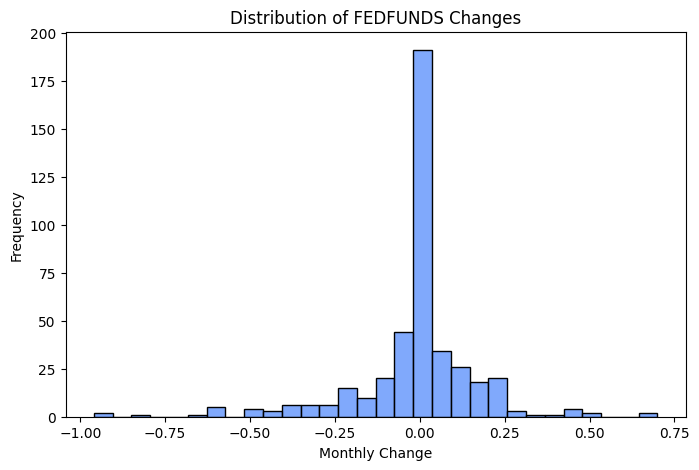

In [124]:
plt.figure(figsize=(8,5))
sns.histplot(dataset['FEDFUNDS_DIFF'], bins=30, kde=False)
plt.title('Distribution of FEDFUNDS Changes')
plt.xlabel('Monthly Change')
plt.ylabel('Frequency')
plt.show()

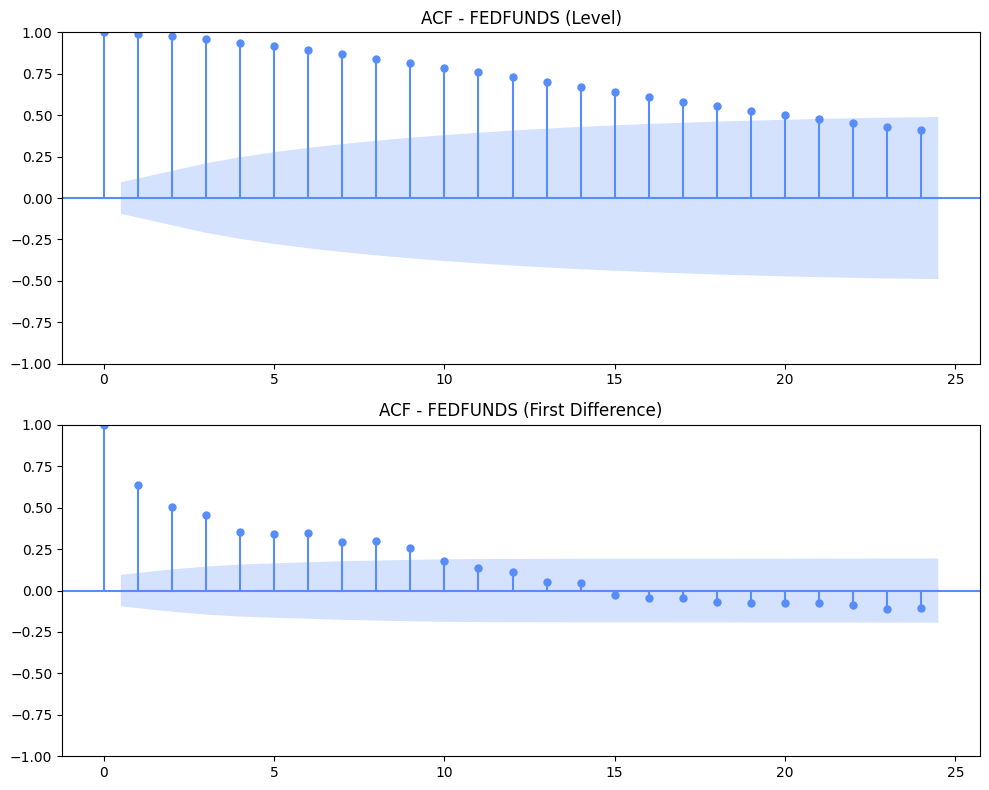

In [125]:
from statsmodels.graphics.tsaplots import plot_acf

fig, ax = plt.subplots(2, 1, figsize=(10,8))

plot_acf(dataset['FEDFUNDS'], lags=24, ax=ax[0])
ax[0].set_title('ACF - FEDFUNDS (Level)')

plot_acf(dataset['FEDFUNDS_DIFF'], lags=24, ax=ax[1])
ax[1].set_title('ACF - FEDFUNDS (First Difference)')

plt.tight_layout()
plt.show()

In [126]:
print("Autocorr FEDFUNDS:", dataset['FEDFUNDS'].autocorr())
print("Autocorr FEDFUNDS_DIFF:", dataset['FEDFUNDS_DIFF'].autocorr())

Autocorr FEDFUNDS: 0.9968013919345885
Autocorr FEDFUNDS_DIFF: 0.6365903039660497


### Models:

In [127]:
X = dataset.drop(columns=['FEDFUNDS', 'FEDFUNDS_DIFF', 'GDPC1'])
y = dataset['FEDFUNDS_DIFF']

In [128]:
# Naive "Previous Period Change" Baseline
min_train_size = 60

y_pred_naive = X['FEDFUNDS_DIFF_LAG1'].iloc[min_train_size:]
y_true_naive = y.iloc[min_train_size:]

y_true_arr = np.array(y_true_naive)
y_pred_arr = np.array(y_pred_naive)

rmse_naive = np.sqrt(mean_squared_error(y_true_arr, y_pred_arr))
mae_naive = mean_absolute_error(y_true_arr, y_pred_arr)
r2_naive = r2_score(y_true_arr, y_pred_arr)

direction_acc_all_naive = np.mean(np.sign(y_true_arr) == np.sign(y_pred_arr))

nonzero_mask = y_true_arr != 0
if np.any(nonzero_mask):
    direction_acc_nonzero_naive = np.mean(
        np.sign(y_true_arr[nonzero_mask]) == np.sign(y_pred_arr[nonzero_mask])
    )
else:
    direction_acc_nonzero_naive = np.nan

print("-" * 30)
print(f"Naive Previous-Period-Change Baseline - RMSE: {rmse_naive:.4f}")
print(f"Naive Previous-Period-Change Baseline - MAE: {mae_naive:.4f}")
print(f"Naive Previous-Period-Change Baseline - R2: {r2_naive:.4f}")
print(f"Directional Accuracy (All): {direction_acc_all_naive:.4f}")
print(f"Directional Accuracy (Nonzero): {direction_acc_nonzero_naive:.4f}")

------------------------------
Naive Previous-Period-Change Baseline - RMSE: 0.1438
Naive Previous-Period-Change Baseline - MAE: 0.0818
Naive Previous-Period-Change Baseline - R2: 0.3237
Directional Accuracy (All): 0.5562
Directional Accuracy (Nonzero): 0.5760


In [129]:
# Taylor Rule Walk-Forward (Expanding Window)
taylor_data = dataset[['FEDFUNDS_DIFF', 'FEDFUNDS_DIFF_LAG1', 'USCPNY=', 'OUTPUT-GAP']]
test_indices = range(min_train_size, len(dataset))

y_pred_taylor = []
y_true_taylor = []
train_r2s_taylor = []

print("Starting Taylor Rule expanding window walk-forward...")
for i in test_indices:
    X_train = taylor_data[['USCPNY=', 'OUTPUT-GAP']].iloc[:i]
    y_train = taylor_data['FEDFUNDS_DIFF'].iloc[:i]

    X_test = taylor_data[['USCPNY=', 'OUTPUT-GAP']].iloc[i:i+1]
    y_test_actual = taylor_data['FEDFUNDS_DIFF'].iloc[i]

    X_train_const = sm.add_constant(X_train, has_constant='add')
    X_test_const = sm.add_constant(X_test, has_constant='add')

    model = sm.OLS(y_train, X_train_const).fit()

    train_r2s_taylor.append(model.rsquared)

    pred = model.predict(X_test_const).iloc[0]

    y_pred_taylor.append(pred)
    y_true_taylor.append(y_test_actual)


y_true_arr = np.array(y_true_taylor)
y_pred_arr = np.array(y_pred_taylor)

rmse_taylor = np.sqrt(mean_squared_error(y_true_arr, y_pred_arr))
mae_taylor = mean_absolute_error(y_true_arr, y_pred_arr)
r2_taylor = r2_score(y_true_arr, y_pred_arr)

direction_acc_all = np.mean(np.sign(y_true_arr) == np.sign(y_pred_arr))

nonzero_mask = y_true_arr != 0
if np.any(nonzero_mask):
    direction_acc_nonzero = np.mean(
        np.sign(y_true_arr[nonzero_mask]) == np.sign(y_pred_arr[nonzero_mask])
    )
else:
    direction_acc_nonzero = np.nan

print("-" * 30)
print(f"Taylor Rule - RMSE: {rmse_taylor:.4f}")
print(f"Taylor Rule - MAE: {mae_taylor:.4f}")
print(f"Taylor Rule - R2: {r2_taylor:.4f}")
print(f"Average Train R2: {np.mean(train_r2s_taylor):.4f}")
print(f"Directional Accuracy (All): {direction_acc_all:.4f}")
print(f"Directional Accuracy (Nonzero): {direction_acc_nonzero:.4f}")

Starting Taylor Rule expanding window walk-forward...
------------------------------
Taylor Rule - RMSE: 0.1855
Taylor Rule - MAE: 0.1161
Taylor Rule - R2: -0.1249
Average Train R2: 0.0715
Directional Accuracy (All): 0.3726
Directional Accuracy (Nonzero): 0.4806


In [130]:
# Augmented Taylor Rule Walk-Forward (Expanding Window)
Y_taylor = taylor_data['FEDFUNDS_DIFF']
X_taylor = taylor_data[['FEDFUNDS_DIFF_LAG1', 'USCPNY=', 'OUTPUT-GAP']]
X_taylor = sm.add_constant(X_taylor)

taylor_model = sm.OLS(Y_taylor, X_taylor).fit(cov_type='HC3')

print(taylor_model.summary())

y_pred_taylor_aug = []
y_true_taylor_aug = []
train_r2s_taylor_aug = []

print("Starting Augmented Taylor Rule expanding window walk-forward...")

for i in test_indices:
    X_train = taylor_data[['USCPNY=', 'OUTPUT-GAP', 'FEDFUNDS_DIFF_LAG1']].iloc[:i]
    y_train = taylor_data['FEDFUNDS_DIFF'].iloc[:i]

    X_test = taylor_data[['USCPNY=', 'OUTPUT-GAP', 'FEDFUNDS_DIFF_LAG1']].iloc[i:i+1]
    y_test_actual = taylor_data['FEDFUNDS_DIFF'].iloc[i]

    X_train_const = sm.add_constant(X_train, has_constant='add')
    X_test_const = sm.add_constant(X_test, has_constant='add')

    model = sm.OLS(y_train, X_train_const).fit()

    train_r2s_taylor_aug.append(model.rsquared)

    pred = model.predict(X_test_const).iloc[0]

    y_pred_taylor_aug.append(pred)
    y_true_taylor_aug.append(y_test_actual)

y_true_arr = np.array(y_true_taylor_aug)
y_pred_arr = np.array(y_pred_taylor_aug)

rmse_taylor_aug = np.sqrt(mean_squared_error(y_true_arr, y_pred_arr))
mae_taylor_aug = mean_absolute_error(y_true_arr, y_pred_arr)
r2_taylor_aug = r2_score(y_true_arr, y_pred_arr)

direction_acc_all = np.mean(np.sign(y_true_arr) == np.sign(y_pred_arr))

nonzero_mask = y_true_arr != 0
if np.any(nonzero_mask):
    direction_acc_nonzero = np.mean(
        np.sign(y_true_arr[nonzero_mask]) == np.sign(y_pred_arr[nonzero_mask])
    )
else:
    direction_acc_nonzero = np.nan

print("-" * 30)
print(f"Augmented Taylor Rule - RMSE: {rmse_taylor_aug:.4f}")
print(f"Augmented Taylor Rule - MAE: {mae_taylor_aug:.4f}")
print(f"Augmented Taylor Rule - R2: {r2_taylor_aug:.4f}")
print(f"Average Train R2: {np.mean(train_r2s_taylor_aug):.4f}")
print(f"Directional Accuracy (All): {direction_acc_all:.4f}")
print(f"Directional Accuracy (Nonzero): {direction_acc_nonzero:.4f}")

                            OLS Regression Results                            
Dep. Variable:          FEDFUNDS_DIFF   R-squared:                       0.406
Model:                            OLS   Adj. R-squared:                  0.401
Method:                 Least Squares   F-statistic:                     49.00
Date:                Sun, 26 Apr 2026   Prob (F-statistic):           3.51e-27
Time:                        21:58:10   Log-Likelihood:                 229.85
No. Observations:                 425   AIC:                            -451.7
Df Residuals:                     421   BIC:                            -435.5
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
const                 -0.0169      0

In [131]:
model_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', StandardScaler()),
    ('mlp', MLPRegressor(hidden_layer_sizes=(32), #128
                         activation='tanh', #relu
                         solver='lbfgs', #adam
                         max_iter=3000,
                         random_state=42,
                         early_stopping=True))
])


In [132]:
# MLP Walk-Forward (Expanding Window)
test_indices = range(min_train_size, len(dataset))

def evaluate_model(y_true, y_pred, model_name):
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)

    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)

    direction_acc_all = np.mean(np.sign(y_true) == np.sign(y_pred))

    nonzero_mask = y_true != 0
    if np.any(nonzero_mask):
        direction_acc_nonzero = np.mean(
            np.sign(y_true[nonzero_mask]) == np.sign(y_pred[nonzero_mask])
        )
    else:
        direction_acc_nonzero = np.nan

    return {
        "Model": model_name,
        "RMSE": rmse,
        "MAE": mae,
        "R2": r2,
        "Directional Accuracy": direction_acc_all,
        "Directional Accuracy Nonzero": direction_acc_nonzero
    }

y_pred_expanding = []
y_true_expanding = []
metrics_history = []
train_r2_history = []

print("Starting MLP expanding window walk-forward...")

for i in test_indices:
    X_train_exp = X.iloc[:i]
    y_train_exp = y.iloc[:i]

    X_test_point = X.iloc[i:i + 1]
    y_test_actual = y.iloc[i]

    model_pipeline.fit(X_train_exp, y_train_exp)

    y_train_pred = model_pipeline.predict(X_train_exp)
    train_r2 = r2_score(y_train_exp, y_train_pred)
    train_r2_history.append(train_r2)

    pred = model_pipeline.predict(X_test_point)[0]

    y_pred_expanding.append(pred)
    y_true_expanding.append(y_test_actual)

    if len(y_true_expanding) >= 2:
        step_results = evaluate_model(
            y_true_expanding,
            y_pred_expanding,
            "MLP Expanding Window"
        )
        step_results["Step"] = i
        step_results["Train R2"] = train_r2
        metrics_history.append(step_results)

final_results = evaluate_model(
    y_true_expanding,
    y_pred_expanding,
    "MLP Expanding Window"
)

final_train_r2 = train_r2_history[-1]
avg_train_r2 = np.mean(train_r2_history)

print("-" * 30)
print(final_results["Model"])
print(f"Expanding Window - RMSE: {final_results['RMSE']:.4f}")
print(f"Expanding Window - MAE: {final_results['MAE']:.4f}")
print(f"Expanding Window - R2: {final_results['R2']:.4f}")
print(f"Average Train R2: {avg_train_r2:.4f}")
print(f"Final Train R2: {final_train_r2:.4f}")
print(f"Directional Accuracy (All): {final_results['Directional Accuracy']:.4f}")
print(f"Directional Accuracy (Nonzero): {final_results['Directional Accuracy Nonzero']:.4f}")

metrics_history_df = pd.DataFrame(metrics_history)

Starting MLP expanding window walk-forward...
------------------------------
MLP Expanding Window
Expanding Window - RMSE: 0.2566
Expanding Window - MAE: 0.1906
Expanding Window - R2: -1.1537
Average Train R2: 0.9984
Final Train R2: 0.9963
Directional Accuracy (All): 0.4466
Directional Accuracy (Nonzero): 0.5760


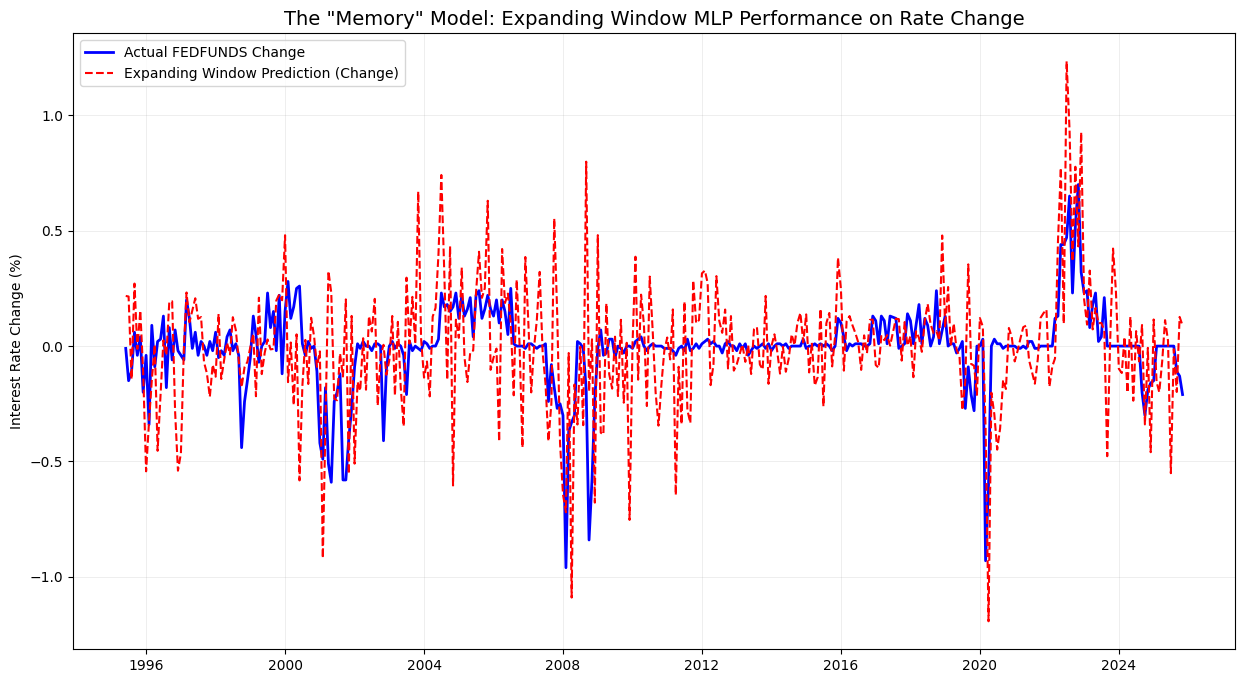

In [133]:
plt.figure(figsize=(15, 8))
full_dates = y.index[min_train_size:]

plt.plot(full_dates, y_true_expanding, label='Actual FEDFUNDS Change', color='blue', linewidth=2)
plt.plot(full_dates, y_pred_expanding, label='Expanding Window Prediction (Change)', color='red', linestyle='--')

plt.title('The "Memory" Model: Expanding Window MLP Performance on Rate Change', fontsize=14)
plt.ylabel('Interest Rate Change (%)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [134]:
# Initial Random Forest Walk-Forward (Expanding Window)
rf_initial_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='mean')),
    ('rf', RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

y_pred_rf_initial = []
y_true_rf_initial = []
train_r2s_initial = []
metrics_history_rf_initial = []

print("Starting INITIAL Random Forest expanding window walk-forward...")

for i in test_indices:
    X_train_exp = X.iloc[:i]
    y_train_exp = y.iloc[:i]

    X_test_point = X.iloc[i:i + 1]
    y_test_actual = y.iloc[i]

    rf_initial_pipeline.fit(X_train_exp, y_train_exp)

    y_train_pred = rf_initial_pipeline.predict(X_train_exp)
    train_r2 = r2_score(y_train_exp, y_train_pred)
    train_r2s_initial.append(train_r2)

    pred = rf_initial_pipeline.predict(X_test_point)[0]

    y_pred_rf_initial.append(pred)
    y_true_rf_initial.append(y_test_actual)

    if len(y_true_rf_initial) >= 2:
        step_results = evaluate_model(
            y_true_rf_initial,
            y_pred_rf_initial,
            "Initial Random Forest"
        )
        step_results["Step"] = i
        step_results["Train R2"] = train_r2
        metrics_history_rf_initial.append(step_results)

final_results_rf_initial = evaluate_model(
    y_true_rf_initial,
    y_pred_rf_initial,
    "Initial Random Forest"
)

final_train_r2_rf_initial = train_r2s_initial[-1]
avg_train_r2_rf_initial = np.mean(train_r2s_initial)

print("-" * 30)
print(final_results_rf_initial["Model"])
print(f"RMSE: {final_results_rf_initial['RMSE']:.4f}")
print(f"MAE: {final_results_rf_initial['MAE']:.4f}")
print(f"R2: {final_results_rf_initial['R2']:.4f}")
print(f"Average Train R2: {avg_train_r2_rf_initial:.4f}")
print(f"Final Train R2: {final_train_r2_rf_initial:.4f}")
print(f"Directional Accuracy (All): {final_results_rf_initial['Directional Accuracy']:.4f}")
print(f"Directional Accuracy (Nonzero): {final_results_rf_initial['Directional Accuracy Nonzero']:.4f}")

metrics_history_rf_initial_df = pd.DataFrame(metrics_history_rf_initial)

Starting INITIAL Random Forest expanding window walk-forward...
------------------------------
Initial Random Forest
RMSE: 0.1365
MAE: 0.0808
R2: 0.3911
Average Train R2: 0.9120
Final Train R2: 0.9273
Directional Accuracy (All): 0.5096
Directional Accuracy (Nonzero): 0.6572


Running 1/8: {'n_estimators': 100, 'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2, 'max_features': 1.0, 'bootstrap': True}
Running 2/8: {'n_estimators': 300, 'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2, 'max_features': 1.0, 'bootstrap': True}
Running 3/8: {'n_estimators': 300, 'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 2, 'max_features': 1.0, 'bootstrap': True}
Running 4/8: {'n_estimators': 300, 'max_depth': 8, 'min_samples_leaf': 1, 'min_samples_split': 2, 'max_features': 1.0, 'bootstrap': True}
Running 5/8: {'n_estimators': 300, 'max_depth': None, 'min_samples_leaf': 2, 'min_samples_split': 2, 'max_features': 1.0, 'bootstrap': True}
Running 6/8: {'n_estimators': 300, 'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 5, 'max_features': 1.0, 'bootstrap': True}
Running 7/8: {'n_estimators': 300, 'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2, 'max_features': 0.7, 'bootstrap': True}
Running 8/8: {'n_est

,key,n_estimators,max_depth,min_samples_leaf,min_samples_split,max_features,bootstrap,RMSE,MAE,R2,Avg Train R2,Final Train R2,Directional Accuracy,Directional Accuracy Nonzero
4,model_5,300,NaN,2,2,1.0,True,0.134277,0.079400,0.410438,0.877745,0.873866,0.495890,0.639576
5,model_6,300,10.0,2,5,1.0,True,0.134452,0.079218,0.408901,0.859334,0.847650,0.501370,0.646643
7,model_8,300,10.0,2,5,0.7,True,0.134967,0.078856,0.404362,0.856650,0.846417,0.517808,0.667845
6,model_7,300,NaN,1,2,0.7,True,0.135629,0.079753,0.398504,0.918161,0.929181,0.501370,0.646643
2,model_3,300,10.0,1,2,1.0,True,0.136258,0.080085,0.392913,0.904630,0.901803,0.506849,0.653710
0,model_1,100,NaN,1,2,1.0,True,0.136466,0.080754,0.391058,0.912020,0.927337,0.509589,0.657244
1,model_2,300,NaN,1,2,1.0,True,0.136544,0.080836,0.390368,0.916920,0.927449,0.520548,0.671378
3,model_4,300,8.0,1,2,1.0,True,0.136662,0.079861,0.389307,0.887409,0.877656,0.506849,0.653710


Best params: {'n_estimators': 300, 'max_depth': None, 'min_samples_leaf': 2, 'min_samples_split': 2, 'max_features': 1.0, 'bootstrap': True}
RMSE: 0.13427718817073764
MAE: 0.07940048570607475
R2: 0.41043831715462253
Avg Train R2: 0.877745264596396
Final Train R2: 0.8738662492424188
Directional Accuracy: 0.4958904109589041
Directional Accuracy Nonzero: 0.6395759717314488


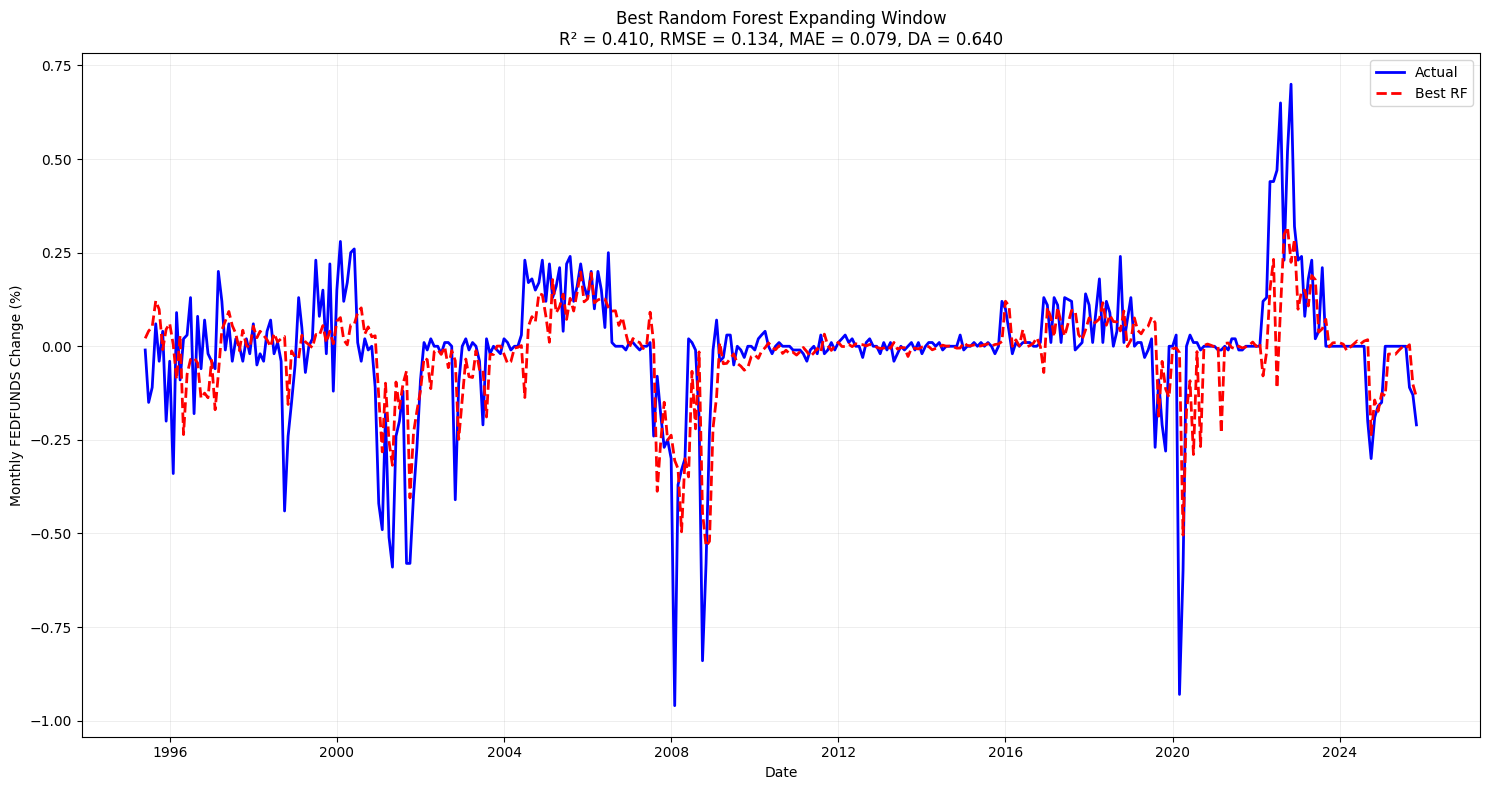

In [135]:
# RF Hyperparameter Tuning
def walk_forward_rf(params, X, y, test_indices):
    pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="mean")),
        ("rf", RandomForestRegressor(
            random_state=42,
            n_jobs=-1,
            **params
        ))
    ])

    preds, actuals = [], []
    train_r2s = []

    for i in test_indices:
        X_train = X.iloc[:i]
        y_train = y.iloc[:i]
        X_test = X.iloc[i:i+1]

        pipe.fit(X_train, y_train)

        train_pred = pipe.predict(X_train)
        train_r2s.append(r2_score(y_train, train_pred))

        preds.append(pipe.predict(X_test)[0])
        actuals.append(y.iloc[i])

    actuals_arr = np.array(actuals)
    preds_arr = np.array(preds)

    direction_acc_all = np.mean(np.sign(actuals_arr) == np.sign(preds_arr))

    nonzero_mask = actuals_arr != 0
    if np.any(nonzero_mask):
        direction_acc_nonzero = np.mean(
            np.sign(actuals_arr[nonzero_mask]) == np.sign(preds_arr[nonzero_mask])
        )
    else:
        direction_acc_nonzero = np.nan

    return {
        "params": params,
        "RMSE": np.sqrt(mean_squared_error(actuals_arr, preds_arr)),
        "MAE": mean_absolute_error(actuals_arr, preds_arr),
        "R2": r2_score(actuals_arr, preds_arr),
        "Avg Train R2": np.mean(train_r2s),
        "Final Train R2": train_r2s[-1],
        "Directional Accuracy": direction_acc_all,
        "Directional Accuracy Nonzero": direction_acc_nonzero,
        "preds": preds,
        "actuals": actuals,
        "train_r2s": train_r2s
    }


candidate_params = [
    {"n_estimators": 100, "max_depth": None, "min_samples_leaf": 1,
     "min_samples_split": 2, "max_features": 1.0, "bootstrap": True},

    {"n_estimators": 300, "max_depth": None, "min_samples_leaf": 1,
     "min_samples_split": 2, "max_features": 1.0, "bootstrap": True},

    {"n_estimators": 300, "max_depth": 10, "min_samples_leaf": 1,
     "min_samples_split": 2, "max_features": 1.0, "bootstrap": True},

    {"n_estimators": 300, "max_depth": 8, "min_samples_leaf": 1,
     "min_samples_split": 2, "max_features": 1.0, "bootstrap": True},

    {"n_estimators": 300, "max_depth": None, "min_samples_leaf": 2,
     "min_samples_split": 2, "max_features": 1.0, "bootstrap": True},

    {"n_estimators": 300, "max_depth": 10, "min_samples_leaf": 2,
     "min_samples_split": 5, "max_features": 1.0, "bootstrap": True},

    {"n_estimators": 300, "max_depth": None, "min_samples_leaf": 1,
     "min_samples_split": 2, "max_features": 0.7, "bootstrap": True},

    {"n_estimators": 300, "max_depth": 10, "min_samples_leaf": 2,
     "min_samples_split": 5, "max_features": 0.7, "bootstrap": True},
]

results = []
outs = {}

for j, params in enumerate(candidate_params, 1):
    print(f"Running {j}/{len(candidate_params)}: {params}")
    out = walk_forward_rf(params, X, y, test_indices)

    key = f"model_{j}"
    outs[key] = out

    results.append({
        "key": key,
        **params,
        "RMSE": out["RMSE"],
        "MAE": out["MAE"],
        "R2": out["R2"],
        "Avg Train R2": out["Avg Train R2"],
        "Final Train R2": out["Final Train R2"],
        "Directional Accuracy": out["Directional Accuracy"],
        "Directional Accuracy Nonzero": out["Directional Accuracy Nonzero"]
    })

tuning_df = pd.DataFrame(results).sort_values("R2", ascending=False)
display(tuning_df)

best_key = tuning_df.iloc[0]["key"]
best_out = outs[best_key]
best_params = best_out["params"]

print("Best params:", best_params)
print("RMSE:", best_out["RMSE"])
print("MAE:", best_out["MAE"])
print("R2:", best_out["R2"])
print("Avg Train R2:", best_out["Avg Train R2"])
print("Final Train R2:", best_out["Final Train R2"])
print("Directional Accuracy:", best_out["Directional Accuracy"])
print("Directional Accuracy Nonzero:", best_out["Directional Accuracy Nonzero"])


rf_dates = y.index[test_indices]

plt.figure(figsize=(15, 8))
plt.plot(rf_dates, best_out["actuals"], label="Actual", color="blue", linewidth=2)
plt.plot(rf_dates, best_out["preds"], label="Best RF", color="red", linestyle="--", linewidth=2)

plt.title(
    f"Best Random Forest Expanding Window\n"
    f"R² = {best_out['R2']:.3f}, "
    f"RMSE = {best_out['RMSE']:.3f}, "
    f"MAE = {best_out['MAE']:.3f}, "
    f"DA = {best_out['Directional Accuracy Nonzero']:.3f}"
)
plt.xlabel("Date")
plt.ylabel("Monthly FEDFUNDS Change (%)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [136]:
# Best Tuned RF Walk-Forward (Expanding Window) + Compute 24 month permutation importace

RUN = True

if RUN:
    rf_pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy='mean')),
        ('rf', RandomForestRegressor(
            n_estimators=300,
            max_depth=None,
            min_samples_leaf=2,
            min_samples_split=2,
            max_features=1.0,
            bootstrap=True,
            random_state=42,
            n_jobs=-1
        ))
    ])

    y_pred_rf = []
    y_true_rf = []

    temporal_importances = []
    temporal_perm_importances = []

    train_r2s = []

    val_window = 24

    print("Starting Random Forest expanding window walk-forward...")

    for i in test_indices:
        X_train_exp = X.iloc[:i]
        y_train_exp = y.iloc[:i]

        X_test_point = X.iloc[i:i+1]
        y_test_actual = y.iloc[i]

        rf_pipeline.fit(X_train_exp, y_train_exp)

        y_train_pred = rf_pipeline.predict(X_train_exp)
        train_r2s.append(r2_score(y_train_exp, y_train_pred))

        temporal_importances.append(
            rf_pipeline.named_steps['rf'].feature_importances_
        )

        X_val = X_train_exp.iloc[-val_window:]
        y_val = y_train_exp.iloc[-val_window:]

        perm = permutation_importance(
            rf_pipeline,
            X_val,
            y_val,
            n_repeats=3,
            random_state=42,
            scoring='neg_mean_squared_error'
        )

        temporal_perm_importances.append(perm.importances_mean)

        pred = rf_pipeline.predict(X_test_point)[0]
        y_pred_rf.append(pred)
        y_true_rf.append(y_test_actual)

    y_true_arr = np.array(y_true_rf)
    y_pred_arr = np.array(y_pred_rf)

    rmse_rf = np.sqrt(mean_squared_error(y_true_arr, y_pred_arr))
    mae_rf = mean_absolute_error(y_true_arr, y_pred_arr)
    r2_rf = r2_score(y_true_arr, y_pred_arr)

    direction_acc_all = np.mean(np.sign(y_true_arr) == np.sign(y_pred_arr))

    nonzero_mask = y_true_arr != 0
    if np.any(nonzero_mask):
        direction_acc_nonzero = np.mean(
            np.sign(y_true_arr[nonzero_mask]) == np.sign(y_pred_arr[nonzero_mask])
        )
    else:
        direction_acc_nonzero = np.nan

    print("-" * 30)
    print(f"Random Forest Expanding Window - RMSE: {rmse_rf:.4f}")
    print(f"Random Forest Expanding Window - MAE: {mae_rf:.4f}")
    print(f"Random Forest Expanding Window - R2: {r2_rf:.4f}")
    print(f"Average Train R2: {np.mean(train_r2s):.4f}")
    print(f"Directional Accuracy (All): {direction_acc_all:.4f}")
    print(f"Directional Accuracy (Nonzero): {direction_acc_nonzero:.4f}")

    feature_names = X.columns

    importance_history_df = pd.DataFrame(
        temporal_importances,
        columns=feature_names,
        index=y.index[test_indices]
    )

    perm_importance_history_df = pd.DataFrame(
        temporal_perm_importances,
        columns=feature_names,
        index=y.index[test_indices]
    )

Starting Random Forest expanding window walk-forward...
------------------------------
Random Forest Expanding Window - RMSE: 0.1343
Random Forest Expanding Window - MAE: 0.0794
Random Forest Expanding Window - R2: 0.4104
Average Train R2: 0.8777
Directional Accuracy (All): 0.4959
Directional Accuracy (Nonzero): 0.6396


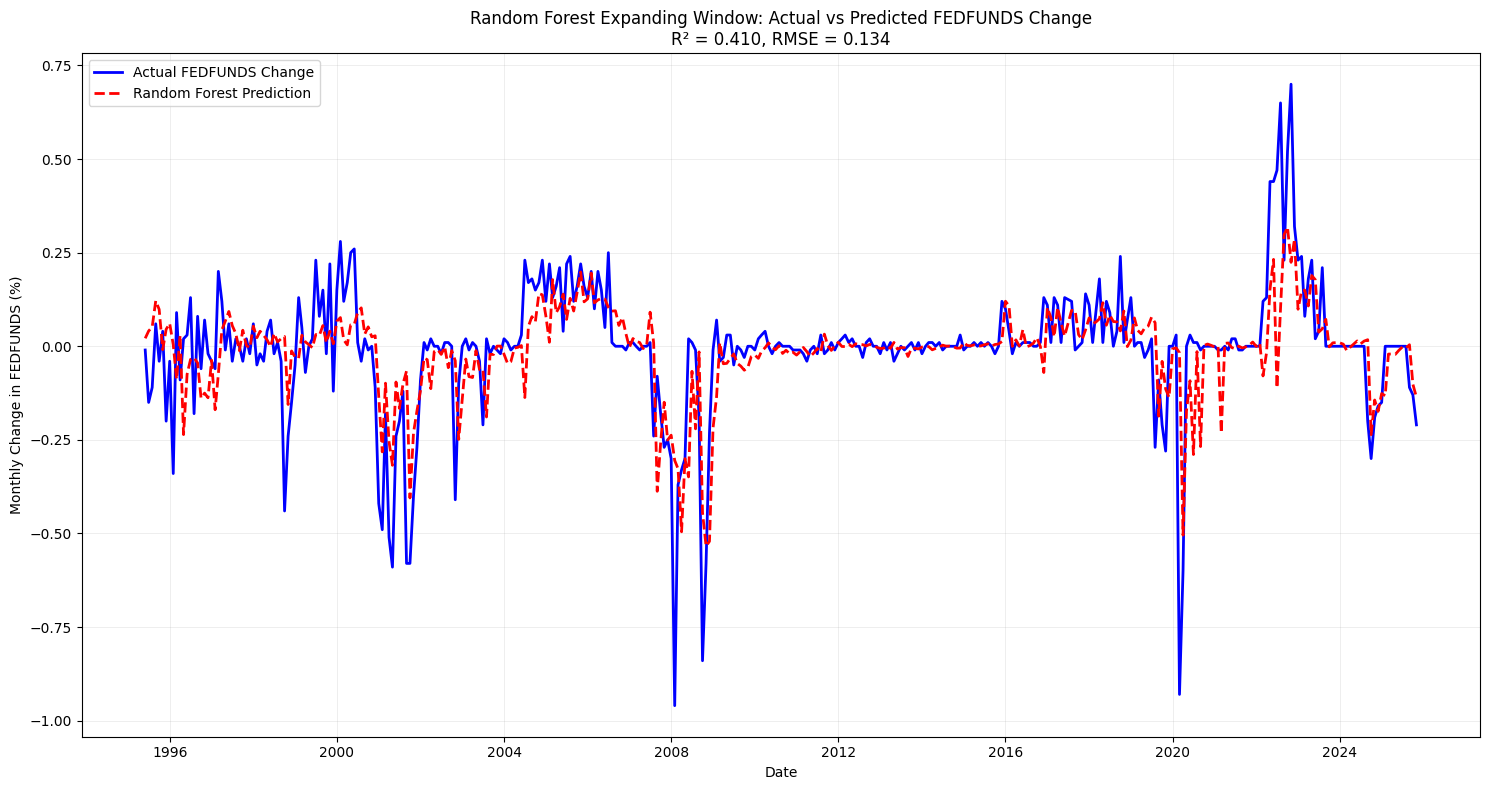

In [137]:
rf_dates = y.index[test_indices]

plt.figure(figsize=(15, 8))
plt.plot(rf_dates, y_true_rf, label='Actual FEDFUNDS Change', color='blue', linewidth=2)
plt.plot(rf_dates, y_pred_rf, label='Random Forest Prediction', color='red', linestyle='--', linewidth=2)

plt.title(f'Random Forest Expanding Window: Actual vs Predicted FEDFUNDS Change\nR² = {r2_rf:.3f}, RMSE = {rmse_rf:.3f}')
plt.xlabel('Date')
plt.ylabel('Monthly Change in FEDFUNDS (%)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### **Feature Importance Analysis (Random Forest)**

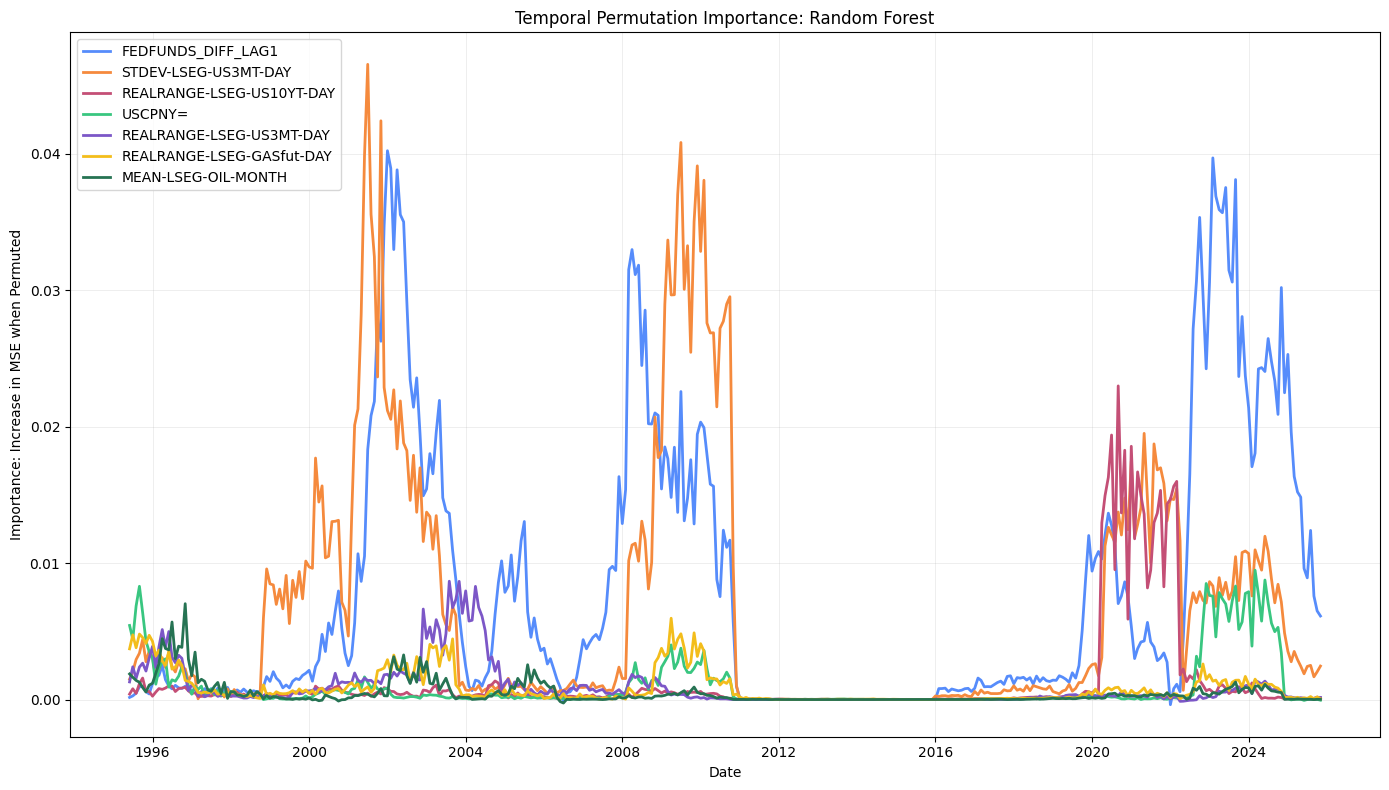

In [138]:
# Plot temporal permutation importance
top_7_perm_features = (
    perm_importance_history_df.mean()
    .sort_values(ascending=False)
    .head(7)
    .index
)

plt.figure(figsize=(14, 8))

for feature in top_7_perm_features:
    plt.plot(
        perm_importance_history_df.index,
        perm_importance_history_df[feature],
        label=feature,
        linewidth=2
    )

plt.title('Temporal Permutation Importance: Random Forest')
plt.xlabel('Date')
plt.ylabel('Importance: Increase in MSE when Permuted')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

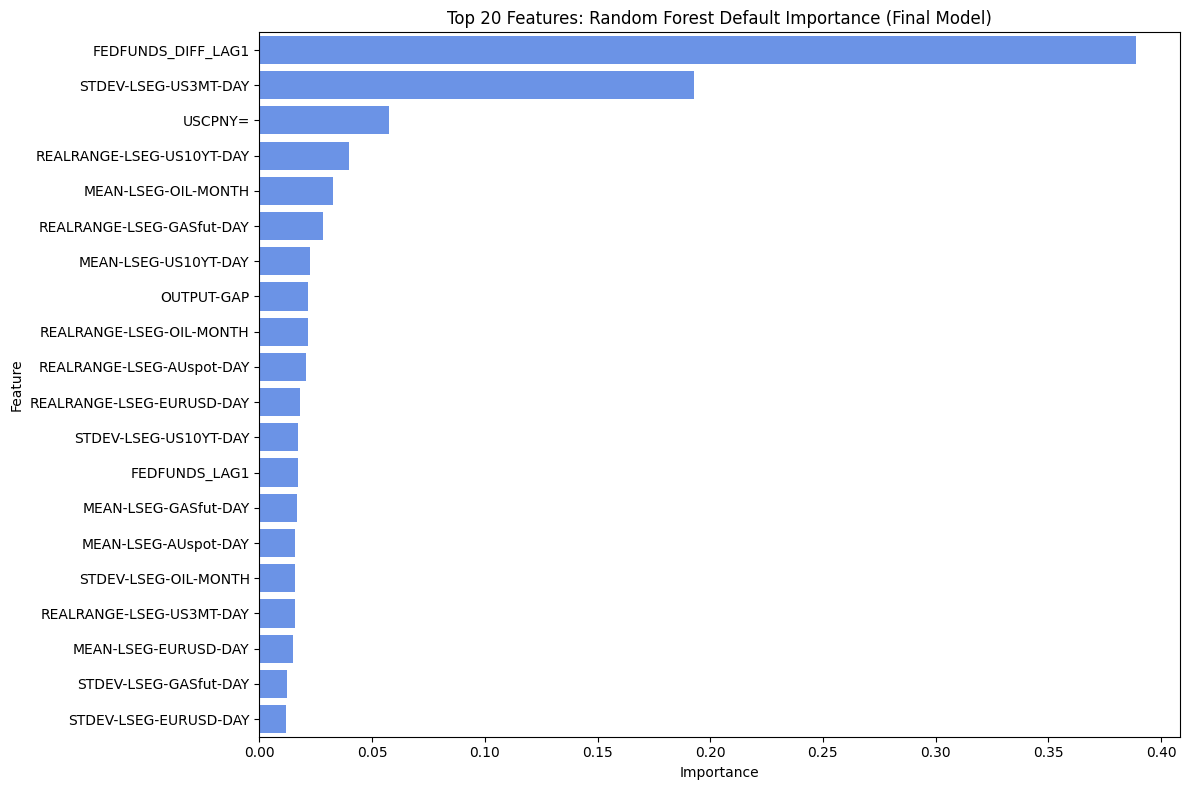

In [139]:
final_rf_model = rf_pipeline.named_steps['rf']
importances = final_rf_model.feature_importances_

feature_names = X.columns
importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
importance_df = importance_df.sort_values(by='Importance', ascending=False)

plt.figure(figsize=(12, 8))
sns.barplot(x='Importance', y='Feature', data=importance_df.head(20))
plt.title('Top 20 Features: Random Forest Default Importance (Final Model)')
plt.tight_layout()
plt.show()

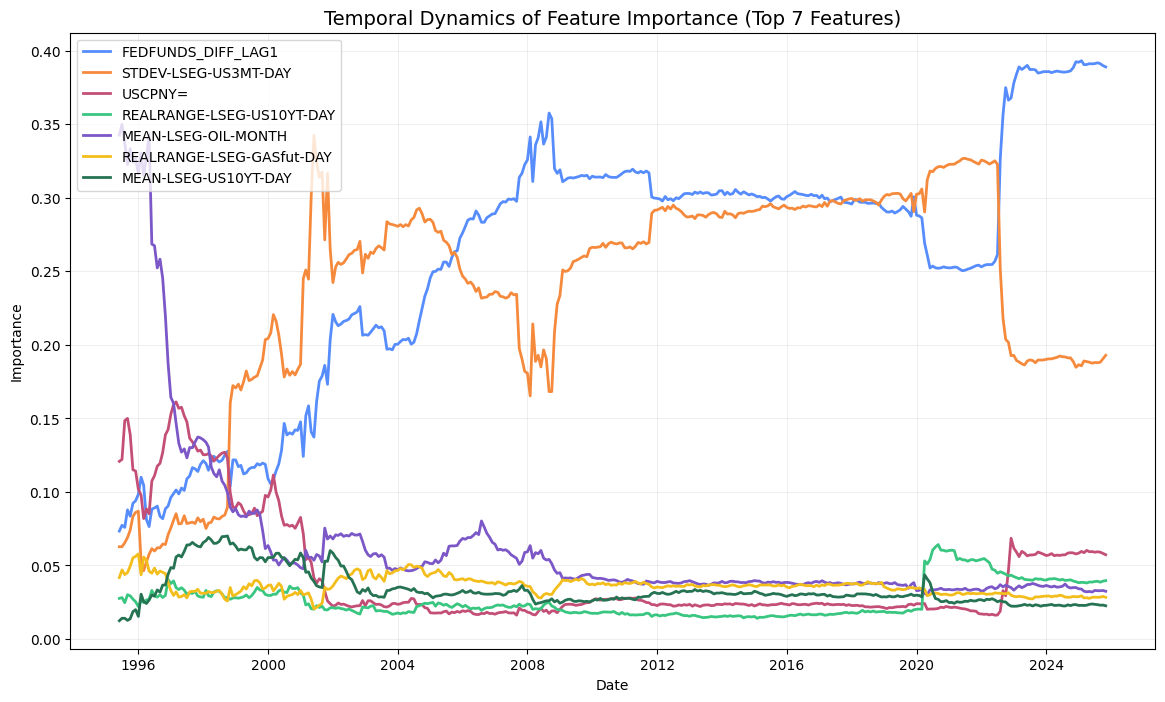

In [140]:
top_7_features = importance_df['Feature'].head(7).tolist()

plt.figure(figsize=(14, 8))
for feature in top_7_features:
    plt.plot(importance_history_df.index, importance_history_df[feature], label=feature, linewidth=2)

plt.title('Temporal Dynamics of Feature Importance (Top 7 Features)', fontsize=14)
plt.xlabel('Date')
plt.ylabel('Importance')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


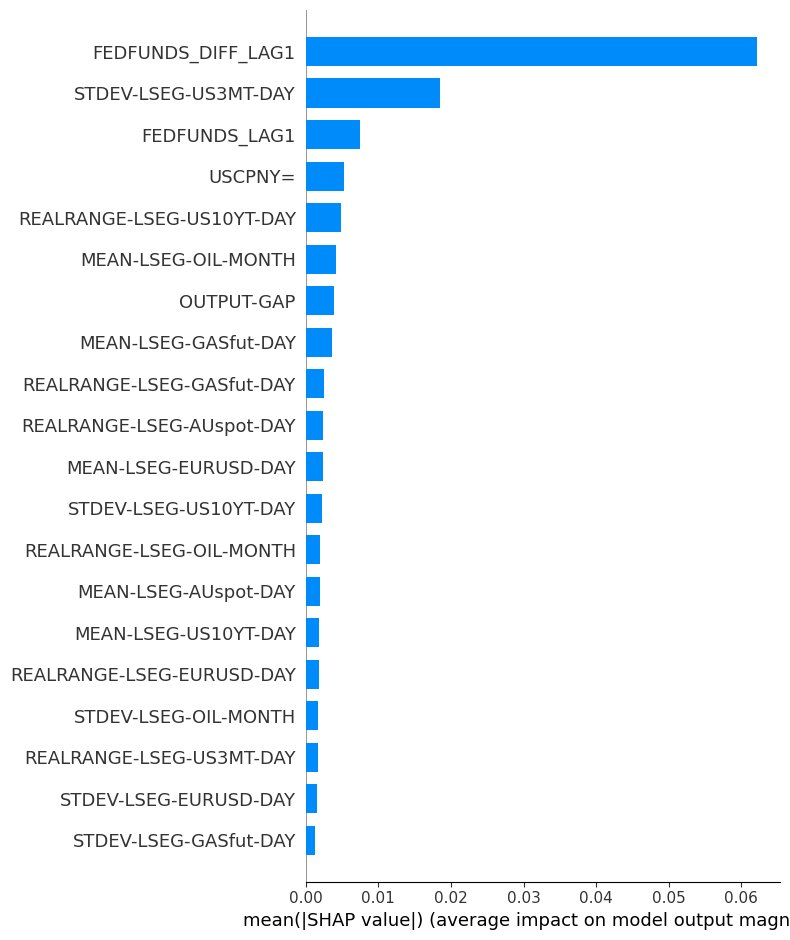

In [141]:
X_processed = rf_pipeline.named_steps['imputer'].transform(X)

X_processed_df = pd.DataFrame(X_processed, columns=X.columns)

explainer = shap.TreeExplainer(final_rf_model)
shap_values = explainer.shap_values(X_processed_df)

shap.summary_plot(
    shap_values,
    X_processed_df,
    plot_type="bar",
    max_display=20
)

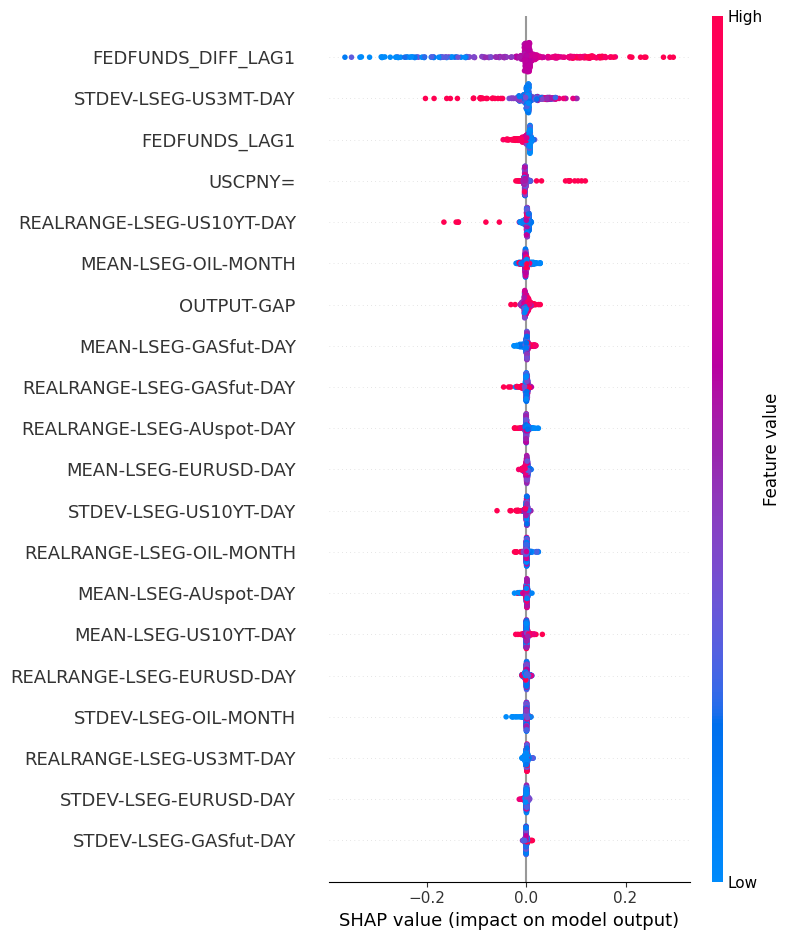

In [142]:
shap.summary_plot(
    shap_values,
    X_processed_df,
    max_display=20
)